<a href="https://colab.research.google.com/github/afrineejhilik71-arch/plant-disease-detection/blob/main/Tomato_run02_size384.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Run 02 — Tomato, larger images (384 × 384)
**Only one change from Run 01:** input size 224 → 384, so small lesions (e.g. White Spot) keep more detail. Same data, same fold, same training protocol. Top-5 models from Run 01 only, to save time.

If a model runs out of GPU memory at batch 32, it is automatically re-run with batch 16 (recorded in the results).
One self-contained notebook: data → cleaning → split → train 8 pretrained CNNs → results.
It needs only `MyDrive/thesis/data/raw/agri_vision.zip`. Nothing from earlier notebooks is required.

**Steps:** 1 GPU · 2 Drive · 3 unzip · 4 audit + clean · 5 folds · 6 settings + training script · 8 train · 9 results

This is **Run 01**, the starting point. Every future improvement gets its own `RUN_NAME`, so all runs are kept side by side and can be compared later.

**Training protocol (v3, fixed):** head warm-up up to 15 epochs → full fine-tuning with learning-rate warm-up (0 → 3e-5, 2 epochs) and cosine decay, early stopping on validation accuracy (patience 10), best weights restored. Class weights, train-only augmentation, 224×224 with padding.

Runtime: **T4 GPU**. After a disconnect: Runtime → Run all (finished models are skipped).

## 1. GPU check

In [ ]:
!nvidia-smi --query-gpu=name,memory.total --format=csv

name, memory.total [MiB]
Tesla T4, 15360 MiB


## 2. Mount Drive, paths, settings

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

!pip install -q imagehash
from pathlib import Path
import json, time, gc, hashlib
import numpy as np, pandas as pd, psutil, imagehash
from PIL import Image, ImageOps
from tqdm.auto import tqdm

PROJECT  = Path('/content/drive/MyDrive/thesis')
ZIP_PATH = PROJECT / 'data/raw/agri_vision.zip'
RUN_NAME = 'run02_size384'
OUT      = PROJECT / 'experiments' / 'tomato' / RUN_NAME
for sub in ['history', 'preds']:
    (OUT / sub).mkdir(parents=True, exist_ok=True)
RESULTS_CSV = OUT / 'results.csv'

CROP, FOLD, SEED, N_FOLDS = 'Tomato', 0, 42, 5
print('Results go to', OUT)

Mounted at /content/drive
Results go to /content/drive/MyDrive/thesis/experiments/tomato/run02_size384


## 3. Unzip the images to local disk (about 1 minute)

In [ ]:
UNZIP_DIR = Path('/content/data/agri_vision')
if not UNZIP_DIR.exists():
    UNZIP_DIR.mkdir(parents=True)
    !unzip -q "{ZIP_PATH}" -d "{UNZIP_DIR}"
    for inner in list(UNZIP_DIR.rglob('*.zip')):
        !unzip -q -o "{inner}" -d "{inner.parent}"
ORIG_DIR = [p for p in UNZIP_DIR.rglob('*') if p.is_dir() and 'original' in p.name.lower()][0]
print('Original images folder:', ORIG_DIR)

Original images folder: /content/data/agri_vision/Agri-Vision4 A Comprehensive Multi-Crop Leaf Disea/Bottle Gourd, Papaya, Tomato, and Zucchini Original Dataset


## 4. Audit and clean (same rules as before, about 1 minute)
All crops are hashed so the folds are identical to the earlier runs; only Tomato is trained afterwards.
Rules: remove unreadable files → remove identical images with different labels → keep one copy of identical images → remove near-identical images with different labels → exclude Zucchini.

In [ ]:
IMG_EXT = {'.jpg', '.jpeg', '.png', '.bmp', '.webp', '.tif', '.tiff'}
rows = []
for p in tqdm(sorted(q for q in ORIG_DIR.rglob('*') if q.suffix.lower() in IMG_EXT), desc='Hashing'):
    parts = p.relative_to(ORIG_DIR).parts
    rec = {'rel_path': '/'.join(parts), 'split': parts[0], 'label_raw': parts[-2]}
    try:
        with Image.open(p) as im:
            im.verify()
        with Image.open(p) as im:
            rec['phash'] = str(imagehash.phash(im.convert('RGB')))
        rec['md5'] = hashlib.md5(p.read_bytes()).hexdigest()
        rec['corrupt'] = False
    except Exception:
        rec['corrupt'] = True
    rows.append(rec)
df = pd.DataFrame(rows).sort_values('rel_path').reset_index(drop=True)
df['label'] = df.label_raw.replace({'Tomato_Downy Mildew': 'Tomato_Downy_Mildew', 'Zucchini_Downy_Midew': 'Zucchini_Downy_Mildew'})
df['crop'] = df.label.str.extract(r'^(Bottle_Gourd|Papaya|Tomato|Zucchini)', expand=False)
df['keep'], df['reason'] = True, ''

def drop(mask, reason):
    m = mask & df.keep
    df.loc[m, 'keep'], df.loc[m, 'reason'] = False, reason
    print(f'{reason:24s} removed {int(m.sum()):5d}   remaining {int(df.keep.sum()):5d}')

drop(df.corrupt.astype(bool), 'unreadable')
g = df[df.keep].groupby('md5').label.nunique();   drop(df.md5.isin(g[g > 1].index), 'label_conflict_exact')
drop(df.keep & df.duplicated('md5'), 'duplicate_copy')
g = df[df.keep].groupby('phash').label.nunique(); drop(df.phash.isin(g[g > 1].index), 'label_conflict_near')
drop(df.crop.eq('Zucchini'), 'excluded_zucchini')

Hashing:   0%|          | 0/5246 [00:00<?, ?it/s]

unreadable               removed     0   remaining  5246
label_conflict_exact     removed   754   remaining  4492
duplicate_copy           removed   463   remaining  4029
label_conflict_near      removed    18   remaining  4011
excluded_zucchini        removed   262   remaining  3749


## 5. Five stratified folds, grouped by near-duplicates; select Tomato

In [ ]:
from sklearn.model_selection import StratifiedGroupKFold
kept = df[df.keep].copy()
kept['fold'] = -1
for k, (_, te) in enumerate(StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
                            .split(kept, kept.label, groups=kept.phash)):
    kept.iloc[te, kept.columns.get_loc('fold')] = k
assert kept.md5.is_unique and kept.groupby('phash').fold.nunique().max() == 1

d = kept[kept.crop == CROP].sort_values('rel_path').reset_index(drop=True)
CLASSES = sorted(d.label.unique())
y = d.label.map({c: i for i, c in enumerate(CLASSES)}).to_numpy()
te, va = (d.fold == FOLD).to_numpy(), (d.fold == (FOLD + 1) % N_FOLDS).to_numpy()
tr = ~(te | va)
d.to_csv(OUT / 'tomato_split.csv', index=False)
print(f'{CROP}: {len(d)} clean images, {len(CLASSES)} classes')
display(pd.crosstab(d.label, np.select([te, va], ['test', 'validation'], 'train')))

Tomato: 795 clean images, 5 classes


col_0,test,train,validation
label,,,
Tomato_Downy_Mildew,8,36,11
Tomato_Healthy,49,151,46
Tomato_Mosaic,37,113,41
Tomato_Spot,43,152,43
Tomato_White_Spot,11,41,13


## 6. Training settings and the training script
Each model is trained in its **own separate process**. When the process ends, all of its memory is released, so the RAM cannot fill up across models (this caused the crash before).

In [ ]:
MODEL_NAMES = ['VGG16', 'ConvNeXtTiny', 'EfficientNetV2B0', 'DenseNet121', 'InceptionV3']   # top 5 of Run 01 (macro-F1)
cfg = {'run': RUN_NAME, 'crop': CROP, 'fold': FOLD, 'seed': SEED, 'n_folds': N_FOLDS,
       'img_size': 384, 'batch': 32, 'head_epochs': 15, 'head_lr': 1e-3,
       'ft_epochs': 40, 'ft_lr': 3e-5, 'warmup_epochs': 2, 'ft_patience': 10,
       'optimizer': 'AdamW(weight_decay=1e-4, clipnorm=1.0)',
       'early_stopping': 'head: val_loss p3; fine-tune: val_accuracy p10; restore best',
       'augmentation': 'flip h+v, rotation 0.1, zoom 0.1, contrast 0.1 (train only)',
       'orig_dir': str(ORIG_DIR), 'out': str(OUT)}
(OUT / 'config.json').write_text(json.dumps(cfg, indent=2))
print(json.dumps(cfg, indent=2))

{
  "run": "run02_size384",
  "crop": "Tomato",
  "fold": 0,
  "seed": 42,
  "n_folds": 5,
  "img_size": 384,
  "batch": 32,
  "head_epochs": 15,
  "head_lr": 0.001,
  "ft_epochs": 40,
  "ft_lr": 3e-05,
  "warmup_epochs": 2,
  "ft_patience": 10,
  "optimizer": "AdamW(weight_decay=1e-4, clipnorm=1.0)",
  "early_stopping": "head: val_loss p3; fine-tune: val_accuracy p10; restore best",
  "augmentation": "flip h+v, rotation 0.1, zoom 0.1, contrast 0.1 (train only)",
  "orig_dir": "/content/data/agri_vision/Agri-Vision4 A Comprehensive Multi-Crop Leaf Disea/Bottle Gourd, Papaya, Tomato, and Zucchini Original Dataset",
  "out": "/content/drive/MyDrive/thesis/experiments/tomato/run02_size384"
}


In [ ]:
%%writefile /content/train_one.py
# Trains ONE model on the split saved by the notebook, then appends its results. Usage: python train_one.py MODEL
import os, sys, json, time
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'
from pathlib import Path
import numpy as np, pandas as pd
from PIL import Image, ImageOps
import tensorflow as tf, keras
from keras import layers
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score, precision_score, recall_score,
                             cohen_kappa_score, matthews_corrcoef, confusion_matrix)
from sklearn.utils.class_weight import compute_class_weight

name = sys.argv[1]
OUT = Path(sys.argv[2]); cfg = json.loads((OUT / 'config.json').read_text())
ORIG_DIR, IMG, BATCH, SEED, FOLD = Path(cfg['orig_dir']), cfg['img_size'], cfg['batch'], cfg['seed'], cfg['fold']
if len(sys.argv) > 3:
    BATCH = int(sys.argv[3])          # fallback batch size after an out-of-memory error
d = pd.read_csv(OUT / 'tomato_split.csv')
CLASSES = sorted(d.label.unique())
y = d.label.map({c: i for i, c in enumerate(CLASSES)}).to_numpy()
te = (d.fold == FOLD).to_numpy(); va = (d.fold == (FOLD + 1) % cfg['n_folds']).to_numpy(); tr = ~(te | va)

A, identity = keras.applications, (lambda x: x)
MODELS = {'VGG16': (A.VGG16, A.vgg16.preprocess_input), 'ResNet50': (A.ResNet50, A.resnet50.preprocess_input),
          'DenseNet121': (A.DenseNet121, A.densenet.preprocess_input),
          'InceptionV3': (A.InceptionV3, A.inception_v3.preprocess_input),
          'Xception': (A.Xception, A.xception.preprocess_input),
          'MobileNetV3Large': (A.MobileNetV3Large, identity),
          'EfficientNetV2B0': (A.EfficientNetV2B0, identity), 'ConvNeXtTiny': (A.ConvNeXtTiny, identity)}
keras.mixed_precision.set_global_policy('float32' if name in {'MobileNetV3Large', 'Xception'} else 'mixed_float16')
keras.utils.set_random_seed(SEED + FOLD)

X = np.stack([np.asarray(ImageOps.pad(Image.open(ORIG_DIR / p).convert('RGB'), (IMG, IMG), color=(0, 0, 0)),
                         dtype=np.uint8) for p in d.rel_path])
augment = keras.Sequential([layers.RandomFlip('horizontal_and_vertical', dtype='float32'),
                            layers.RandomRotation(0.1, dtype='float32'), layers.RandomZoom(0.1, dtype='float32'),
                            layers.RandomContrast(0.1, dtype='float32')])
ctor, prep = MODELS[name]

def make_ds(mask, train):
    ds = tf.data.Dataset.from_tensor_slices((X[mask], y[mask]))
    if train:
        ds = ds.shuffle(int(mask.sum()), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.batch(BATCH).map(lambda a, b: (tf.cast(a, tf.float32), b), num_parallel_calls=tf.data.AUTOTUNE)
    if train:
        ds = ds.map(lambda a, b: (augment(a, training=True), b), num_parallel_calls=tf.data.AUTOTUNE)
    return ds.map(lambda a, b: (prep(a), b), num_parallel_calls=tf.data.AUTOTUNE).prefetch(tf.data.AUTOTUNE)

base = ctor(include_top=False, weights='imagenet', input_shape=(IMG, IMG, 3)); base.trainable = False
inp = keras.Input((IMG, IMG, 3))
x = layers.GlobalAveragePooling2D()(base(inp, training=False))
model = keras.Model(inp, layers.Dense(len(CLASSES), activation='softmax', dtype='float32')(layers.Dropout(0.3)(x)))
ds_tr, ds_va, ds_te = make_ds(tr, True), make_ds(va, False), make_ds(te, False)
cw = dict(enumerate(compute_class_weight('balanced', classes=np.arange(len(CLASSES)), y=y[tr])))
opt = lambda lr: keras.optimizers.AdamW(learning_rate=lr, weight_decay=1e-4, clipnorm=1.0)

t0 = time.perf_counter()
model.compile(opt(cfg['head_lr']), 'sparse_categorical_crossentropy', metrics=['accuracy'])
h1 = model.fit(ds_tr, validation_data=ds_va, epochs=cfg['head_epochs'], class_weight=cw, verbose=0,
               callbacks=[keras.callbacks.EarlyStopping('val_loss', patience=3, restore_best_weights=True)])
base.trainable = True
steps = int(np.ceil(tr.sum() / BATCH))
sched = keras.optimizers.schedules.CosineDecay(0.0, (cfg['ft_epochs'] - cfg['warmup_epochs']) * steps,
                                               warmup_target=cfg['ft_lr'], warmup_steps=cfg['warmup_epochs'] * steps)
model.compile(opt(sched), 'sparse_categorical_crossentropy', metrics=['accuracy'])
h2 = model.fit(ds_tr, validation_data=ds_va, epochs=cfg['ft_epochs'], class_weight=cw, verbose=0,
               callbacks=[keras.callbacks.EarlyStopping('val_accuracy', mode='max', patience=cfg['ft_patience'],
                                                        restore_best_weights=True),
                          keras.callbacks.TerminateOnNaN()])
minutes = (time.perf_counter() - t0) / 60
pred = model.predict(ds_te, verbose=0).argmax(1); true = y[te]

(OUT / 'history').mkdir(exist_ok=True); (OUT / 'preds').mkdir(exist_ok=True)
pd.concat([pd.DataFrame(h1.history).assign(phase='head'), pd.DataFrame(h2.history).assign(phase='finetune')]
          ).to_csv(OUT / 'history' / f'{name}.csv', index=False)
pd.DataFrame({'rel_path': d.rel_path[te].values, 'y_true': true, 'y_pred': pred}).to_csv(OUT / 'preds' / f'{name}.csv', index=False)
best = int(np.nanargmax(h2.history['val_accuracy']))
row = {'crop': cfg['crop'], 'model': name, 'fold': FOLD, 'img_size': IMG, 'batch': BATCH, 'n_train': int(tr.sum()), 'n_val': int(va.sum()), 'n_test': int(te.sum()),
       'accuracy': accuracy_score(true, pred), 'balanced_accuracy': balanced_accuracy_score(true, pred),
       'macro_precision': precision_score(true, pred, average='macro', zero_division=0),
       'macro_recall': recall_score(true, pred, average='macro', zero_division=0),
       'macro_f1': f1_score(true, pred, average='macro', zero_division=0),
       'weighted_f1': f1_score(true, pred, average='weighted', zero_division=0),
       'cohen_kappa': cohen_kappa_score(true, pred), 'mcc': matthews_corrcoef(true, pred),
       'best_val_acc': float(h2.history['val_accuracy'][best]), 'train_acc_at_best': float(h2.history['accuracy'][best]),
       'epochs_head': len(h1.history['loss']), 'epochs_finetune': len(h2.history['loss']),
       'params_M': model.count_params() / 1e6, 'train_minutes': minutes,
       'per_class_f1': json.dumps(dict(zip(CLASSES, np.round(f1_score(true, pred, average=None,
                                  labels=range(len(CLASSES)), zero_division=0), 3).tolist()))),
       'confusion_matrix': json.dumps(confusion_matrix(true, pred, labels=range(len(CLASSES))).tolist())}
res = OUT / 'results.csv'
new = pd.DataFrame([row])
if res.exists():
    new = pd.concat([pd.read_csv(res), new], ignore_index=True)
new.to_csv(res, index=False)
print(f"{name:17s} acc {row['accuracy']:.3f}  macroF1 {row['macro_f1']:.3f}  "
      f"train_acc {row['train_acc_at_best']:.3f}  ({minutes:.1f} min)")

Writing /content/train_one.py


## 8. Train — one separate process per model (about 75–110 minutes for 5 models at 384 px)

In [ ]:
import subprocess
done = set(pd.read_csv(RESULTS_CSV).model) if RESULTS_CSV.exists() else set()
todo = [m for m in MODEL_NAMES if m not in done]
print(f'{len(done)} finished, {len(todo)} to do')
for i, name in enumerate(todo, 1):
    p = subprocess.run(['python', '/content/train_one.py', name, str(OUT)], capture_output=True, text=True)
    if p.returncode != 0 and ('ResourceExhausted' in p.stderr or 'OOM' in p.stderr):
        print(f'      {name}: out of GPU memory at batch 32 -> retrying with batch 16')
        p = subprocess.run(['python', '/content/train_one.py', name, str(OUT), '16'], capture_output=True, text=True)
    last = [l for l in p.stdout.strip().splitlines() if l.strip()]
    if p.returncode == 0 and last:
        print(f'[{i}/{len(todo)}] {last[-1]}   | RAM now {psutil.virtual_memory().used/1e9:.1f} GB')
    else:
        print(f'[{i}/{len(todo)}] {name} FAILED:\n' + p.stderr[-1500:])
print('Done.')

0 finished, 5 to do
[1/5] VGG16             acc 0.777  macroF1 0.725  train_acc 0.870  (18.0 min)   | RAM now 1.8 GB
[2/5] ConvNeXtTiny      acc 0.770  macroF1 0.693  train_acc 0.854  (19.8 min)   | RAM now 1.8 GB
[3/5] EfficientNetV2B0  acc 0.682  macroF1 0.648  train_acc 0.682  (16.5 min)   | RAM now 1.9 GB
[4/5] DenseNet121       acc 0.770  macroF1 0.703  train_acc 0.876  (31.7 min)   | RAM now 1.9 GB
[5/5] InceptionV3       acc 0.770  macroF1 0.712  train_acc 0.915  (18.2 min)   | RAM now 1.8 GB
Done.


In [ ]:
import subprocess
EXTRA = ['ResNet50', 'Xception', 'MobileNetV3Large']      # the remaining 3 models
done = set(pd.read_csv(RESULTS_CSV).model)
todo = [m for m in EXTRA if m not in done]
print(f'{len(todo)} extra models to train')
for i, name in enumerate(todo, 1):
    p = subprocess.run(['python', '/content/train_one.py', name, str(OUT)], capture_output=True, text=True)
    if p.returncode != 0 and ('ResourceExhausted' in p.stderr or 'OOM' in p.stderr):
        print(f'      {name}: out of GPU memory at batch 32 -> retrying with batch 16')
        p = subprocess.run(['python', '/content/train_one.py', name, str(OUT), '16'], capture_output=True, text=True)
    last = [l for l in p.stdout.strip().splitlines() if l.strip()]
    if p.returncode == 0 and last:
        print(f'[{i}/{len(todo)}] {last[-1]}   | RAM now {psutil.virtual_memory().used/1e9:.1f} GB')
    else:
        print(f'[{i}/{len(todo)}] {name} FAILED:\n' + p.stderr[-1500:])
print('Done.')

3 extra models to train
[1/3] ResNet50          acc 0.770  macroF1 0.717  train_acc 0.929  (17.9 min)   | RAM now 1.9 GB
[2/3] Xception          acc 0.716  macroF1 0.601  train_acc 0.803  (22.6 min)   | RAM now 1.9 GB
[3/3] MobileNetV3Large  acc 0.676  macroF1 0.563  train_acc 0.712  (13.8 min)   | RAM now 1.9 GB
Done.


## 9. Results table, per-class F1, Excel and figure

run02_size384 — Tomato, fold 0, 148 test images (%):


,model,accuracy,balanced_accuracy,macro_f1,weighted_f1,mcc,train_acc_at_best,params_M,epochs_finetune
0,VGG16,77.70,71.18,72.55,77.56,69.51,87.02,14.72,24.0
5,ResNet50,77.03,72.71,71.73,75.59,69.15,92.90,23.60,30.0
4,InceptionV3,77.03,68.28,71.18,76.27,68.43,91.48,21.81,30.0
3,DenseNet121,77.03,70.68,70.31,75.64,68.92,87.63,7.04,34.0
1,ConvNeXtTiny,77.03,72.77,69.27,76.44,69.70,85.40,27.82,25.0
2,EfficientNetV2B0,68.24,69.30,64.78,67.71,58.18,68.15,5.93,18.0
6,Xception,71.62,60.91,60.08,71.00,61.71,80.32,20.87,25.0
7,MobileNetV3Large,67.57,66.63,56.33,63.81,59.19,71.20,3.00,18.0



F1 per class (%):


,Tomato_Downy_Mildew,Tomato_Healthy,Tomato_Mosaic,Tomato_Spot,Tomato_White_Spot
VGG16,66.7,90.9,68.4,76.7,60.0
ResNet50,77.8,88.7,60.0,79.6,52.6
InceptionV3,61.5,90.6,63.9,76.7,63.2
DenseNet121,66.7,88.7,57.1,83.5,55.6
ConvNeXtTiny,53.8,91.1,60.0,82.6,58.8
EfficientNetV2B0,77.8,84.3,48.3,69.8,43.8
Xception,37.5,87.6,57.1,78.2,40.0
MobileNetV3Large,45.2,87.6,22.7,80.0,46.2


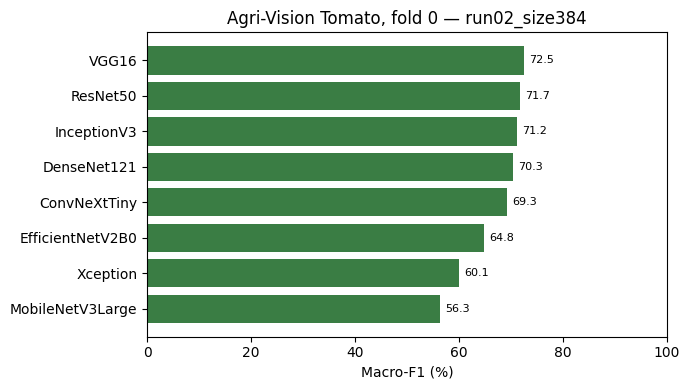

Saved Excel and figure in /content/drive/MyDrive/thesis/experiments/tomato/run02_size384


In [ ]:
import matplotlib.pyplot as plt
r = pd.read_csv(RESULTS_CSV).drop_duplicates('model', keep='last').sort_values('macro_f1', ascending=False)
cols = ['accuracy', 'balanced_accuracy', 'macro_f1', 'weighted_f1', 'mcc', 'train_acc_at_best']
table = r[['model'] + cols].copy(); table[cols] = (100 * table[cols]).round(2)
table[['params_M', 'epochs_finetune']] = r[['params_M', 'epochs_finetune']].round(2).values
print(f'{RUN_NAME} — Tomato, fold {FOLD}, {int(r.n_test.iloc[0])} test images (%):'); display(table)

per_class = pd.DataFrame({m: json.loads(s) for m, s in zip(r.model, r.per_class_f1)}).T * 100
print('\nF1 per class (%):'); display(per_class.round(1))

with pd.ExcelWriter(OUT / f'{RUN_NAME}_results.xlsx') as xw:
    table.to_excel(xw, sheet_name='summary', index=False)
    per_class.round(1).to_excel(xw, sheet_name='per_class_f1')
    r.drop(columns=['confusion_matrix']).to_excel(xw, sheet_name='all_columns', index=False)
    pd.Series(cfg).astype(str).to_frame('value').to_excel(xw, sheet_name='protocol')

fig, ax = plt.subplots(figsize=(7, 4))
t = table.sort_values('macro_f1')
ax.barh(t.model, t.macro_f1, color='#3a7d44'); ax.set_xlim(0, 100); ax.set_xlabel('Macro-F1 (%)')
ax.set_title(f'Agri-Vision Tomato, fold {FOLD} — {RUN_NAME}')
for yv, v in enumerate(t.macro_f1): ax.text(v + 1, yv, f'{v:.1f}', va='center', fontsize=8)
plt.tight_layout(); fig.savefig(OUT / f'{RUN_NAME}_macro_f1.png', dpi=200); plt.show()
print('Saved Excel and figure in', OUT)